Эту строку вы можете раскомментировать если будет необходимо.

In [60]:
#pip install --force-reinstall tensorflow

Импорт библиотек

Задание:  Используя документацию библиотеки, прочитайте о назначении каждого модуля. Зафиксируйте эти сведения в дополнительной текстовой ячейке.

In [61]:
from keras.layers import Dense      #создаёт отдельный полносвязный слой, который добавляется внутрь модели
from keras.models import Sequential #создаёт модель нейросети и определяет последовательность слоёв
from keras.datasets import mnist    #загружает готовый набор данных картинок с цифрами
from keras import utils             #преобразует метки цифр в формат One Hot Encoding для обучения нейросети
import numpy as np                  #вся работа с массивами для нейросети
import matplotlib.pyplot as plt     #графики
%matplotlib inline

Инициализация наборов данных

In [62]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()    #автомат 60к - обуч. и 10к - тест

Изменение форматов  данных

Задание: Используя дополнительные инструкции, определите исходный формат данных. Попытайтесь определить какие преобразования и для чего производятся в результате выполнения нижеприведённого кода.

In [63]:
X_train = X_train.reshape(60000, 784)   #меняем размерности матриц для обучения
X_test = X_test.reshape(10000, 784)     #из двумерных в одномерные в 784 значения

X_train = X_train.astype('float32')     #меняем тип данных с int на float32 для
X_test = X_test.astype('float32')       #получения значений от 0 до 1 при делении
X_train /= 255    #нормализация
X_test /= 255

Пример выходных данных

In [64]:
n = 100             #x_train = изображения в массиве, y_train = ответы
print(y_train[n])   #вытащили ответ на 100 изображение из датасета

5


Преобразуем метки в формат one hot encoding

In [65]:
Y_train = utils.to_categorical(y_train, 10)   #подготавливаем ответы для быстрого
Y_test = utils.to_categorical(y_test, 10)     #сравнения с выходом нейросети

  Правильный ответ в формате one hot encoding

In [66]:
print(Y_train[n])

[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


Создаем нейронную сеть

In [67]:
model = Sequential()

Добавляем уровни сети

Создаем нейронную сеть:

Задание: Используя документацию, определите основные параметры метода add. Запишите полученные сведения в дополнительной текстовой ячейке. Опишите топологию создаваемой в программе нейронной сети и ее особенности (используемые функции активации, …).

In [68]:
model.add(Dense(784, input_dim=784, activation="relu"))   #полносвязный слой входа
model.add(Dense(200, input_dim=784, activation="relu"))   #скрытый слой relu(-1 = 0)
model.add(Dense(10, activation="softmax"))                #выходной слой, softmax переводит зачения в вероятности


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Компилируем сеть

Задание: Используя справочный материал, поясните значение каждого параметра метода compile

In [69]:
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
print(model.summary())

#loss-функция ошибки (перекрёстная энтропия)
#optumizer-алгоритм изминения весов (постепенная подгонка к правильному ответу)
#metrics-оценка качества работы во время обучения (процент распознаный правильно)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 784)            │       615,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 200)            │       157,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │         2,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 774,450 (2.95 MB)

 Trainable params: 774,450 (2.95 MB)

 Non-trainable params: 0 (0.00 B)

None


Обучаем нейронную сеть

Для обучения нейронной сети будем использовать обучающую выборку X_train и правильные ответы для нее Y_train.

Параметр bath_size определяет количество образцов, которые будут одновременно использованы для обучения сети. Этот параметр оказывает влияние на алгоритм обучения.

Параметр epochs отвечает за число эпох обучения.

Параметр validation_split отвечает за долю первоначальных исходных данных, которые пойдут для тестирования обученной сети. Остальная часть исходных данных пойдет для обучения сети.

Параметр verbose отвечает за настройку алгоритма обучения сети.

In [70]:
history = model.fit(X_train, Y_train, batch_size=200, epochs=25, validation_split=0.2, verbose=2)

Epoch 1/25
240/240 - 3s - 12ms/step - accuracy: 0.9186 - loss: 0.2746 - val_accuracy: 0.9617 - val_loss: 0.1300
Epoch 2/25
240/240 - 1s - 4ms/step - accuracy: 0.9717 - loss: 0.0957 - val_accuracy: 0.9697 - val_loss: 0.0984
Epoch 3/25
240/240 - 1s - 4ms/step - accuracy: 0.9820 - loss: 0.0601 - val_accuracy: 0.9754 - val_loss: 0.0849
Epoch 4/25
240/240 - 1s - 4ms/step - accuracy: 0.9882 - loss: 0.0384 - val_accuracy: 0.9765 - val_loss: 0.0793
Epoch 5/25
240/240 - 1s - 4ms/step - accuracy: 0.9909 - loss: 0.0286 - val_accuracy: 0.9740 - val_loss: 0.0847
Epoch 6/25
240/240 - 1s - 4ms/step - accuracy: 0.9931 - loss: 0.0212 - val_accuracy: 0.9792 - val_loss: 0.0775
Epoch 7/25
240/240 - 1s - 4ms/step - accuracy: 0.9967 - loss: 0.0120 - val_accuracy: 0.9790 - val_loss: 0.0817
Epoch 8/25
240/240 - 1s - 5ms/step - accuracy: 0.9960 - loss: 0.0124 - val_accuracy: 0.9799 - val_loss: 0.0796
Epoch 9/25
240/240 - 1s - 5ms/step - accuracy: 0.9977 - loss: 0.0070 - val_accuracy: 0.9787 - val_loss: 0.0910


Качество работы сети на тестовых данных

In [71]:
scores = model.evaluate(X_test, Y_test, verbose=0)
print("Точность работы на тестовых данных: %.2f%%" % (scores[1]*100))

Точность работы на тестовых данных: 97.73%


Задание: Используя справочный материал, изучите атрибуты объекта History. Приведите их краткое описание.

In [72]:
history_dict = history.history    #хранит информацию о процессе обучения нейронной сети и результатах каждой эпохи
#словарь, содержащий значения потерь (loss), точности (accuracy) и показатели на проверочной выборке (val_loss, val_accuracy) для каждой эпохи

Для построения графика качества обучения используется библиотека matplotlib

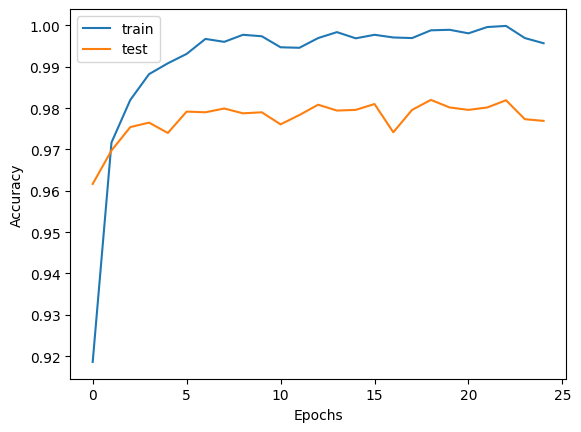

In [73]:

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='test')
plt.legend()
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

Теперь можно распознать рукописную цифру из набора данных, используя обученную сеть:

In [74]:
n_rec = 488   ;                         #индекс изображения из тестовой выборки

In [75]:
x = X_test[n_rec]                       #достаём изображение из тестовой выборки по индексу
x = np.expand_dims(x, axis=0)           #меняет форму с (784,) на (1, 784), что бы коректно передать размер пакета из 1 изображения

In [76]:
prediction = model.predict(x)           #передам пакет в нейросеть и получаем значения предсказаний на каждое выходное

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 336ms/step


In [77]:
print(prediction)

[[1.6863635e-13 3.2804519e-14 8.9874304e-16 1.4534625e-12 2.8090896e-10
  1.6374750e-17 9.0646513e-18 3.4810990e-09 1.6816959e-10 1.0000000e+00]]


In [78]:
prediction = np.argmax(prediction)      #ищем max индекс в массиве предсказаний (ответ)
print(prediction)

9


In [79]:
print(y_test[n_rec])                    #правильный ответ

9


Используя графический редактор paint создайте изображение рукописной цифры. Используйте базовый инструмент «Карандаш». Размер изображения должен быть 28 на 28 пикселей или близкий к этому, поскольку при преобразовании изображение сильно искажается.
Сохраните изображение в формате jpeg и загрузите на свой google-диск.


Подключение google-диска

In [80]:
from google.colab import drive
drive.mount('/gdrive')

Drive already mounted at /gdrive; to attempt to forcibly remount, call drive.mount("/gdrive", force_remount=True).


Перейдите по ссылке, выберите свой аккаунт google и нажмите «разрешить». Далее следуйте инструкциям. Скопируйте код, перейдите в приложение и вставьте его в нужное поле:

Проверка google-диска ...

In [81]:
!ls "/gdrive/My Drive"

 1			   Бекапы
'Colab Notebooks'	   Дизайн
 Obsidian		  ' Док-синхронизация.gdoc'
 Otchet_po_praktike.docx   майн
 PracticeIntro.ipynb	  'Новая таблица.gsheet'
 t2_1.gdoc		  'Опрос клиента.gdoc'
 UNIK			   Отчёт_по_практической_работе_3.docx
 VPN			   прогинж-2.docx.pdf
 Андан.docx		  'Резюме_Замятин Андрей Александрович.pdf'
 Андан.gdoc


Установка библиотек для обработки изображения

In [82]:
!pip install opencv-python
!pip install scipy


Импорт библиотек для обработки изображения.  Загрузка и обработка изображения с google-диска

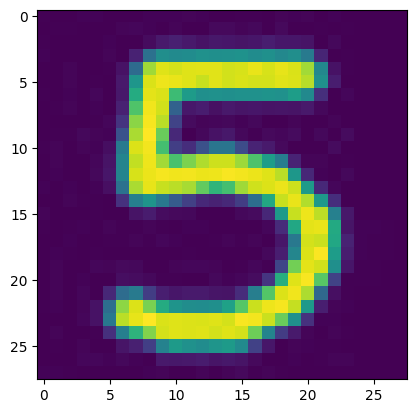

In [83]:
import cv2
import scipy.misc
import matplotlib.pyplot as plt

img=cv2.imread("/gdrive/My Drive/1/img4.jpg", cv2.IMREAD_GRAYSCALE)
#resolution = (28, 28)
#img = cv2.resize(img, resolution)
#img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img_data = (255.0-img.reshape(-1))/255    #подготовка данных в вектор для нейросети (784 входных нейрона)
plt.imshow(img_data.reshape(28,28))       #возвращаем обратно изображение в 28 на 28 для отображения


Задание: Поясните, какого рода преобразования изображения были произведены, для чего

In [84]:
x=np.expand_dims(img_data,axis=0)    #меняет форму с (784,) на (1, 784), что бы коректно передать размер пакета из 1 изображения

Используя обученную сеть, пробуем распознать вновь созданное изображение

In [85]:
prediction = model.predict(x)        #передам пакет в нейросеть и получаем значения предсказаний на каждое выходное
print(prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
[[8.7134301e-29 6.1012754e-19 6.3299613e-27 2.3296648e-06 7.8288985e-28
  9.9999762e-01 4.4609169e-24 7.9139409e-19 2.4785923e-20 4.7504530e-16]]


Оцените результат

In [86]:
prediction = np.argmax(prediction)   #ищем max индекс в массиве предсказаний (ответ)
print(prediction)

5
